In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv('/content/spam.csv', encoding='latin-1')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
df = df[['v1', 'v2']].copy()

df.columns = ['label', 'message']

df = df.dropna()
df = df.drop_duplicates()

print("Dataset cleaned successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset cleaned successfully!
Dataset shape: (5169, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Number of messages in each class:
label
ham     4516
spam     653
Name: count, dtype: int64

Class distribution in percentage:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


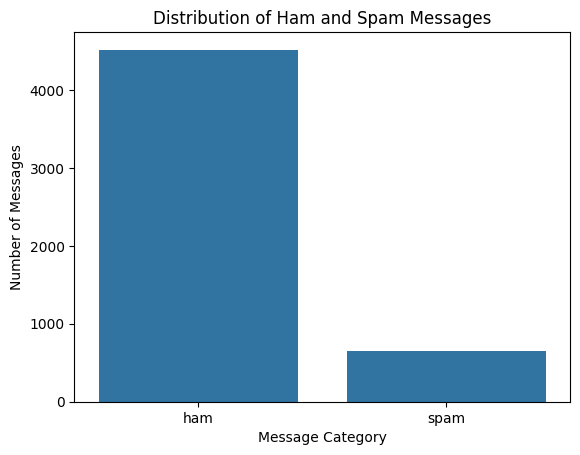

In [ ]:
print("Number of messages in each class:")
print(df['label'].value_counts())

print("\nClass distribution in percentage:")
print((df['label'].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x='label')
plt.title('Distribution of Ham and Spam Messages')
plt.xlabel('Message Category')
plt.ylabel('Number of Messages')
plt.show()

In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_message'] = df['message'].apply(clean_text)

print("Text preprocessing completed!")

display(df[['message', 'clean_message']].head())

Text preprocessing completed!


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [ ]:
from sklearn.model_selection import train_test_split

X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Data splitting completed!
Training messages: 4135
Testing messages: 1034

Training label distribution:
label
ham     3613
spam     522
Name: count, dtype: int64

Testing label distribution:
label
ham     903
spam    131
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed!")
print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Number of vocabulary features:", len(tfidf.vocabulary_))

TF-IDF feature extraction completed!
Training feature shape: (4135, 5000)
Testing feature shape: (1034, 5000)
Number of vocabulary features: 5000


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
import time

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": LinearSVC(random_state=42),
    "Naive Bayes": MultinomialNB()
}

predictions = {}
training_times = {}
prediction_times = {}

for name, model in models.items():
    start_train = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    training_times[name] = time.perf_counter() - start_train

    start_predict = time.perf_counter()
    predictions[name] = model.predict(X_test_tfidf)
    prediction_times[name] = time.perf_counter() - start_predict

    print(f"{name} trained successfully!")
    print(f"Training time: {training_times[name]:.4f} seconds")
    print(f"Prediction time: {prediction_times[name]:.4f} seconds")
    print("-" * 40)

print("All four models have been trained and tested!")

Decision Tree trained successfully!
Training time: 1.6983 seconds
Prediction time: 0.0052 seconds
----------------------------------------
KNN trained successfully!
Training time: 0.0192 seconds
Prediction time: 0.2088 seconds
----------------------------------------
SVM trained successfully!
Training time: 0.0388 seconds
Prediction time: 0.0006 seconds
----------------------------------------
Naive Bayes trained successfully!
Training time: 0.0344 seconds
Prediction time: 0.0025 seconds
----------------------------------------
All four models have been trained and tested!


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Spam Precision": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Spam Recall": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Spam F1-Score": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Training Time (s)": training_times[name],
        "Prediction Time (s)": prediction_times[name]
    })

results_df = pd.DataFrame(results)

print("Model evaluation completed!")
display(results_df.round(4))

Model evaluation completed!


,Model,Accuracy,Spam Precision,Spam Recall,Spam F1-Score,Training Time (s),Prediction Time (s)
0,Decision Tree,0.9603,0.8571,0.8244,0.8405,1.6983,0.0052
1,KNN,0.9110,1.0000,0.2977,0.4588,0.0192,0.2088
2,SVM,0.9826,0.9829,0.8779,0.9274,0.0388,0.0006
3,Naive Bayes,0.9681,1.0000,0.7481,0.8559,0.0344,0.0025


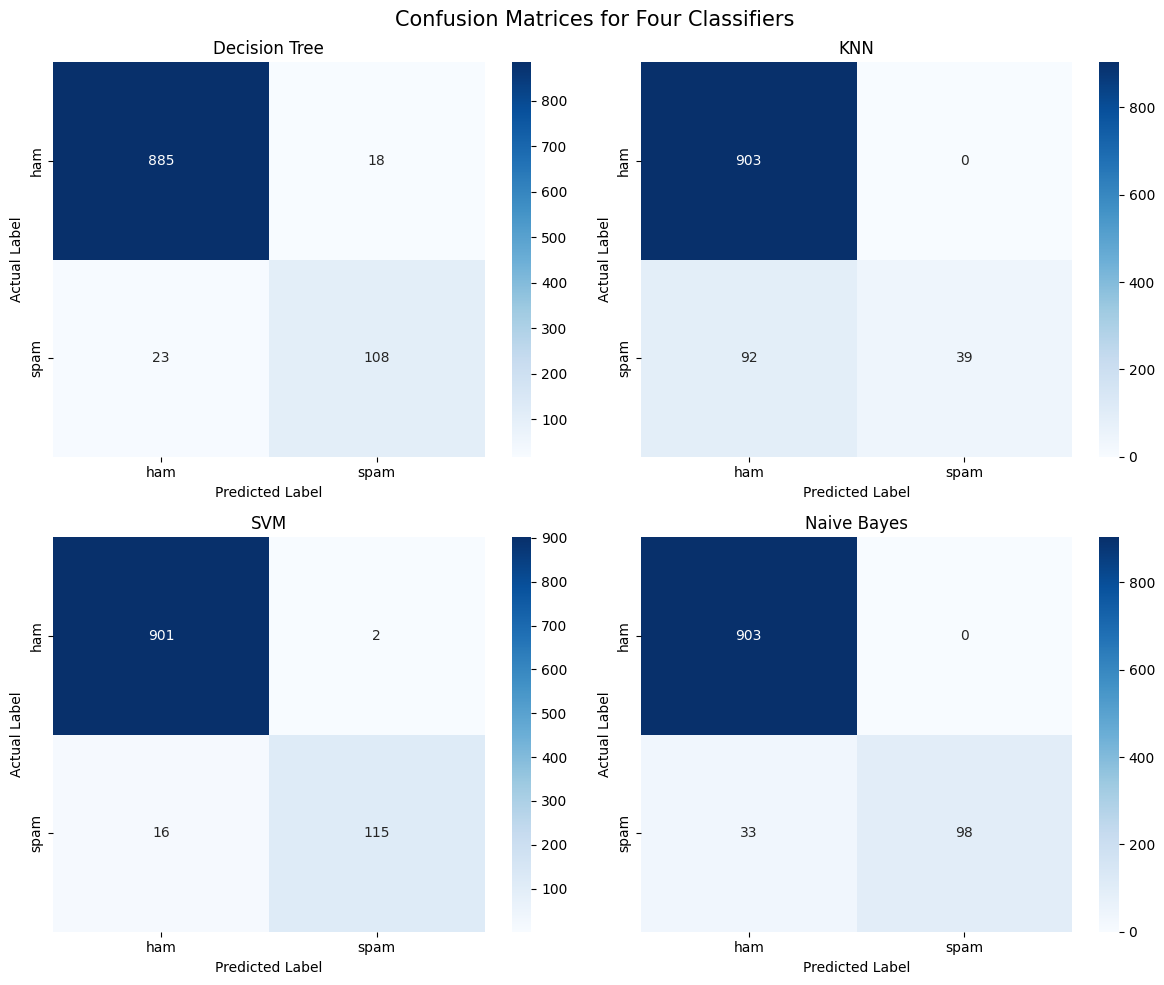

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

labels = ["ham", "spam"]

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrices for Four Classifiers", fontsize=15)
plt.tight_layout()
plt.show()

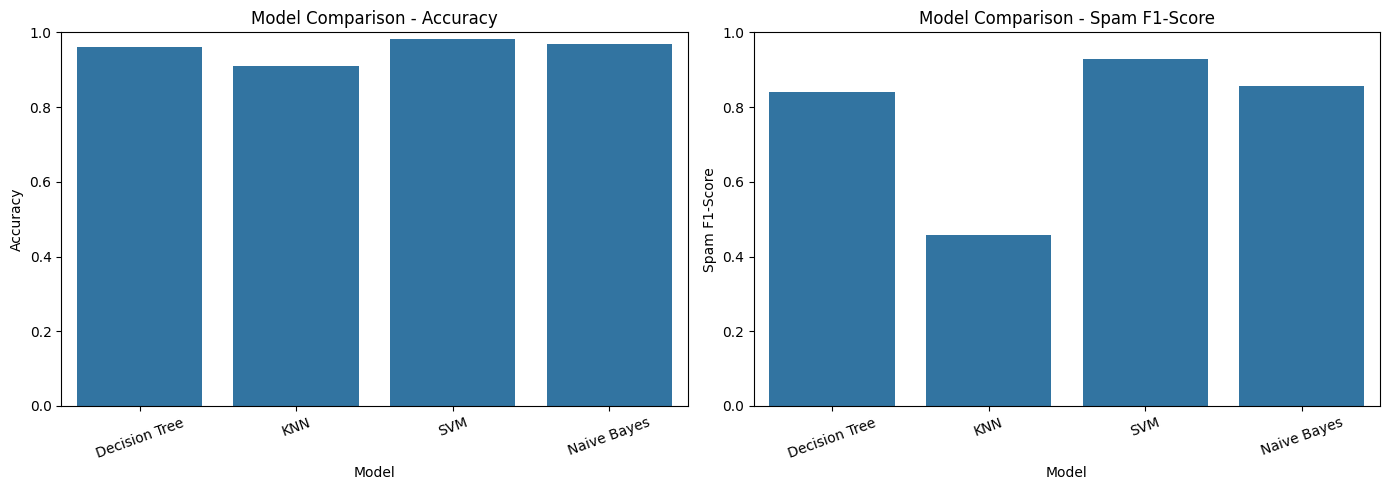

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=results_df, x="Model", y="Accuracy", ax=axes[0])
axes[0].set_title("Model Comparison - Accuracy")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Accuracy")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=results_df, x="Model", y="Spam F1-Score", ax=axes[1])
axes[1].set_title("Model Comparison - Spam F1-Score")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Spam F1-Score")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time

alpha_values = [0.1, 0.5, 1.0, 2.0]
what_if_results = []

for alpha in alpha_values:
    model = MultinomialNB(alpha=alpha)

    start = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    y_pred = model.predict(X_test_tfidf)
    predict_time = time.perf_counter() - start

    what_if_results.append({
        "Alpha": alpha,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Spam Precision": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Spam Recall": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Spam F1-Score": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    })

what_if_df = pd.DataFrame(what_if_results)

print("What-if experiment completed!")
display(what_if_df.round(4))

What-if experiment completed!


,Alpha,Accuracy,Spam Precision,Spam Recall,Spam F1-Score,Training Time (s),Prediction Time (s)
0,0.1,0.9816,0.9746,0.8779,0.9237,0.0255,0.0005
1,0.5,0.9797,0.9911,0.8473,0.9136,0.0147,0.0005
2,1.0,0.9681,1.0000,0.7481,0.8559,0.0156,0.0005
3,2.0,0.9555,1.0000,0.6489,0.7870,0.0198,0.0005


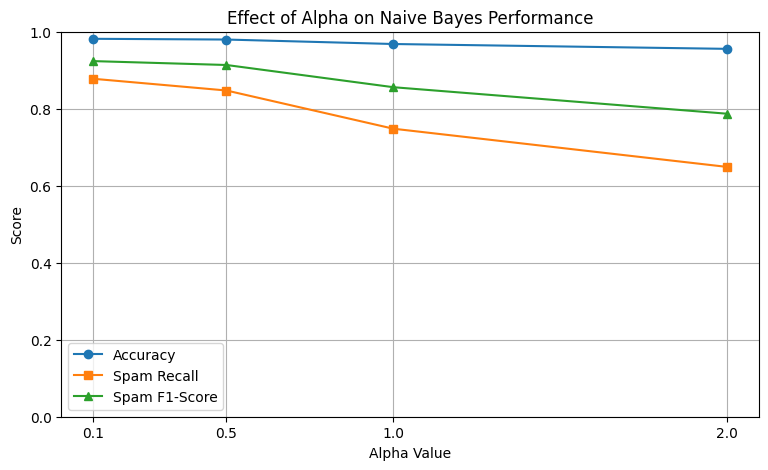

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    what_if_df["Alpha"],
    what_if_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    what_if_df["Alpha"],
    what_if_df["Spam Recall"],
    marker="s",
    label="Spam Recall"
)

plt.plot(
    what_if_df["Alpha"],
    what_if_df["Spam F1-Score"],
    marker="^",
    label="Spam F1-Score"
)

plt.title("Effect of Alpha on Naive Bayes Performance")
plt.xlabel("Alpha Value")
plt.ylabel("Score")
plt.xticks(what_if_df["Alpha"])
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
best_model = results_df.loc[results_df["Accuracy"].idxmax()]
best_f1_model = results_df.loc[results_df["Spam F1-Score"].idxmax()]
best_nb = what_if_df.loc[what_if_df["Spam F1-Score"].idxmax()]

print("FINAL MODEL COMPARISON")
print("-" * 40)

print("Best classifier by accuracy:", best_model["Model"])
print(f"Accuracy: {best_model['Accuracy']:.2%}")

print("\nBest classifier by spam F1-score:", best_f1_model["Model"])
print(f"Spam F1-score: {best_f1_model['Spam F1-Score']:.2%}")

print("\nBest Naive Bayes alpha:", best_nb["Alpha"])
print(f"Accuracy: {best_nb['Accuracy']:.2%}")
print(f"Spam Precision: {best_nb['Spam Precision']:.2%}")
print(f"Spam Recall: {best_nb['Spam Recall']:.2%}")
print(f"Spam F1-score: {best_nb['Spam F1-Score']:.2%}")

FINAL MODEL COMPARISON
----------------------------------------
Best classifier by accuracy: SVM
Accuracy: 98.26%

Best classifier by spam F1-score: SVM
Spam F1-score: 92.74%

Best Naive Bayes alpha: 0.1
Accuracy: 98.16%
Spam Precision: 97.46%
Spam Recall: 87.79%
Spam F1-score: 92.37%
